# Câu 2 & Câu 3: Xây dựng các mô hình dữ liệu, tập huấn luyện, tiêu chí đánh giá & So sánh hiệu quả các mô hình

**Mục tiêu:**
1. Huấn luyện và đánh giá toàn diện **9 họ mô hình học máy** trong `MODEL_ZOO`: Logistic Regression (`lr`), Complement Naive Bayes (`nb`), Calibrated Linear SVM (`svm_linear`), RBF SVM (`svm_rbf`), Decision Tree (`dt`), Random Forest (`rf`), Cosine KNN (`knn`), XGBoost (`xgb`), và LightGBM (`lgbm`).
2. So sánh giữa hai cách biểu diễn đặc trưng: `word_tfidf` (unigram + bigram) và `word+char` (kết hợp word n-gram và char n-gram 2–5).
3. Đánh giá bằng 5-fold CV trên `train` và đo lường độc lập trên `val` theo tiêu chí chính **F1 lớp dương (`f1_pos`)**, **PR-AUC**, **Recall**, **ROC-AUC**, **MCC** và tốc độ suy luận.

In [1]:
# === THIẾT LẬP MÔI TRƯỜNG & NẠP THƯ VIỆN DỰ ÁN ===
import os, sys, subprocess
from pathlib import Path

os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
REPO_URL = "https://github.com/nhungoc-1/DoAnKHDL_DeTai_Tweet-Hate.git"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    print("[SETUP] Đang khởi tạo môi trường Google Colab...", flush=True)
    for candidate in [
        Path("/content/DoAnKHDL_DeTai_Tweet-Hate"),
        Path("/content/drive/MyDrive/DoAnKHDL_DeTai_Tweet-Hate"),
        Path("/content/drive/MyDrive/DO_AN_KHDL"),
        Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd(),
    ]:
        if (candidate / "config.yaml").exists():
            PROJECT_DIR = candidate
            subprocess.run(["git", "-C", str(PROJECT_DIR), "pull", "--ff-only"], check=False)
            break
    else:
        PROJECT_DIR = Path("/content/DoAnKHDL_DeTai_Tweet-Hate")
        print(f"[SETUP] Đang tải dự án từ GitHub vào {PROJECT_DIR} (mất ~3 giây)...", flush=True)
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(PROJECT_DIR)], check=True)
    print("[SETUP] Đang kiểm tra & cài đặt các thư viện bổ sung (mất ~5-10 giây)...", flush=True)
    subprocess.run([
        sys.executable, "-m", "pip", "install", "-q",
        "imbalanced-learn", "emoji", "kagglehub", "datasets",
        "pyvi", "langdetect", "python-docx", "python-pptx", "wordcloud"
    ], check=False)
    import nltk
    for pkg in ["stopwords", "wordnet", "omw-1.4"]:
        nltk.download(pkg, quiet=True)
else:
    PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.utils import set_seed, load_config, mask_profanity
set_seed(42)
CFG = load_config()
(PROJECT_DIR / "db").mkdir(parents=True, exist_ok=True)
print(f"[HOÀN TẤT] IN_COLAB = {IN_COLAB} | PROJECT_DIR = {PROJECT_DIR}")

[SETUP] PROJECT_DIR = D:\DO_AN_KHDL


## 1. Bảng So sánh Kết quả 9 Mô hình trên Tập Validation & Kiểm định Paired t-test

In [2]:
import pandas as pd
from IPython.display import display, Image

comp_df = pd.read_csv('reports/model_comparison.csv')
display(comp_df)

ttest_df = pd.read_csv('reports/tables/P5_paired_ttest.csv')
print('=== Kiểm định Paired t-test trên 5-fold CV F1 giữa Top-3 cấu hình ===')
display(ttest_df)

,run_id,model_key,model_name,vectorizer,balance,cv_f1_mean,cv_f1_std,precision_pos,recall_pos,f1_pos,...,roc_auc,pr_auc,mcc,tn,fp,fn,tp,fit_seconds,predict_ms_per_1k,note
0,lr__word+char,lr,Logistic Regression,word+char,ros,0.6478,0.0186,0.5795,0.7365,0.6486,...,0.9466,0.7090,0.6262,3825,148,73,204,3.859,111.112,Train toàn bộ tập train
1,bilstm_deep__embedding_128,bilstm_deep,BiLSTM (PyTorch Embedding),embedding_128,pos_weight,0.5973,0.0000,0.5663,0.6318,0.5973,...,0.9133,0.6168,0.5685,3839,134,102,175,83.860,77.395,Deep Learning bonus (cpu)
2,svm_linear__word+char,svm_linear,Linear SVM (Calibrated),word+char,ros,0.5569,0.0284,0.8323,0.4657,0.5972,...,0.9342,0.7039,0.6046,3947,26,148,129,4.239,110.788,Train toàn bộ tập train
3,lr__word_tfidf,lr,Logistic Regression,word_tfidf,ros,0.5876,0.0117,0.5053,0.6895,0.5832,...,0.9320,0.6377,0.5571,3786,187,86,191,0.597,13.099,Train toàn bộ tập train
4,svm_linear__word_tfidf,svm_linear,Linear SVM (Calibrated),word_tfidf,ros,0.5492,0.0321,0.7529,0.4621,0.5727,...,0.9195,0.6267,0.5688,3931,42,149,128,0.946,18.859,Train toàn bộ tập train
5,nb__word+char,nb,Complement Naive Bayes,word+char,ros,0.5713,0.0075,0.4270,0.8448,0.5673,...,0.9559,0.7403,0.5640,3659,314,43,234,2.563,110.100,Train toàn bộ tập train
6,lgbm__word_tfidf,lgbm,LightGBM,word_tfidf,ros,0.5416,0.0170,0.4562,0.6209,0.5260,...,0.9035,0.5713,0.4943,3768,205,105,172,3.593,25.428,Train toàn bộ tập train
7,rf__word_tfidf,rf,Random Forest,word_tfidf,ros,0.5344,0.0237,0.4447,0.6245,0.5195,...,0.9072,0.5950,0.4881,3757,216,104,173,1.888,31.193,Train toàn bộ tập train
8,nb__word_tfidf,nb,Complement Naive Bayes,word_tfidf,ros,0.5252,0.0148,0.3790,0.7690,0.5077,...,0.9353,0.6765,0.4963,3624,349,64,213,0.515,14.050,Train toàn bộ tập train
9,xgb__word_tfidf,xgb,XGBoost,word_tfidf,ros,0.4990,0.0150,0.4053,0.6643,0.5034,...,0.8955,0.5513,0.4765,3703,270,93,184,23.328,23.811,Train toàn bộ tập train


=== Kiểm định Paired t-test trên 5-fold CV F1 giữa Top-3 cấu hình ===


,run_a,run_b,mean_diff_f1,t_statistic,p_value,significant_at_005
0,lr__word+char,svm_linear__word+char,0.0909,8.7064,0.0010,True
1,lr__word+char,lr__word_tfidf,0.0602,12.4889,0.0002,True
2,svm_linear__word+char,lr__word_tfidf,-0.0307,-3.6158,0.0224,True


## 2. Biểu đồ So sánh F1 / PR-AUC, Đường cong ROC & PR, và Lưới 3×3 Ma trận Nhầm lẫn

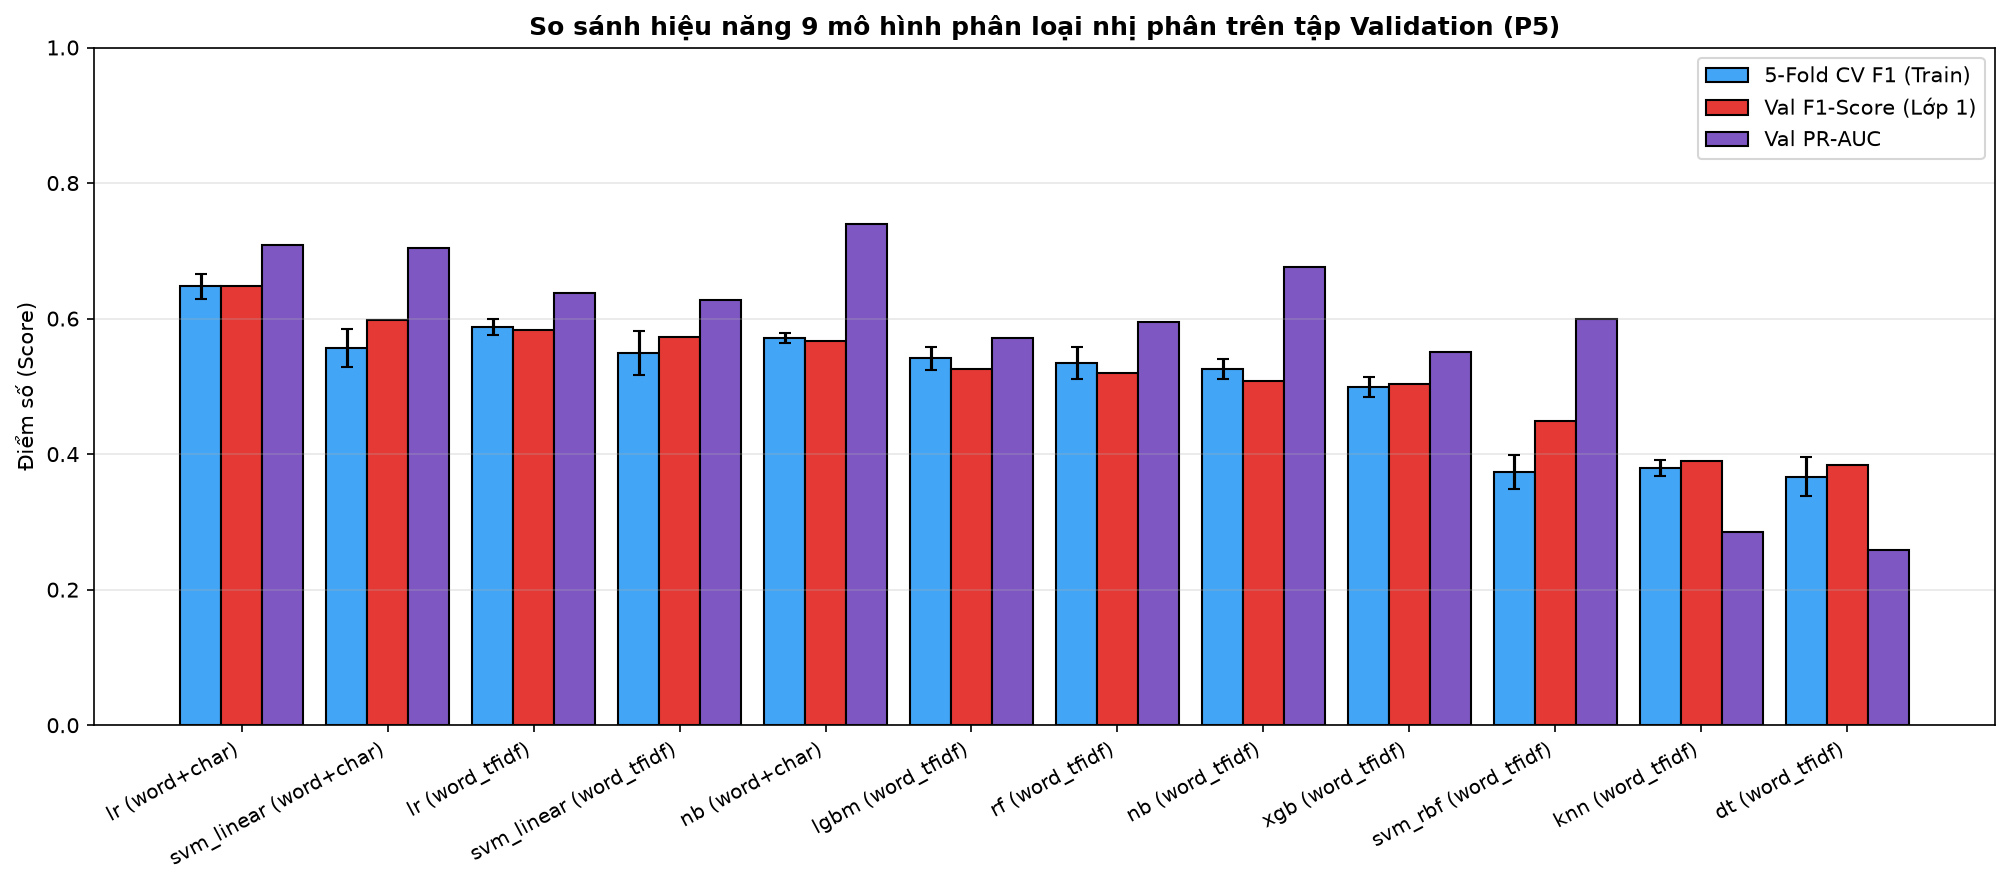

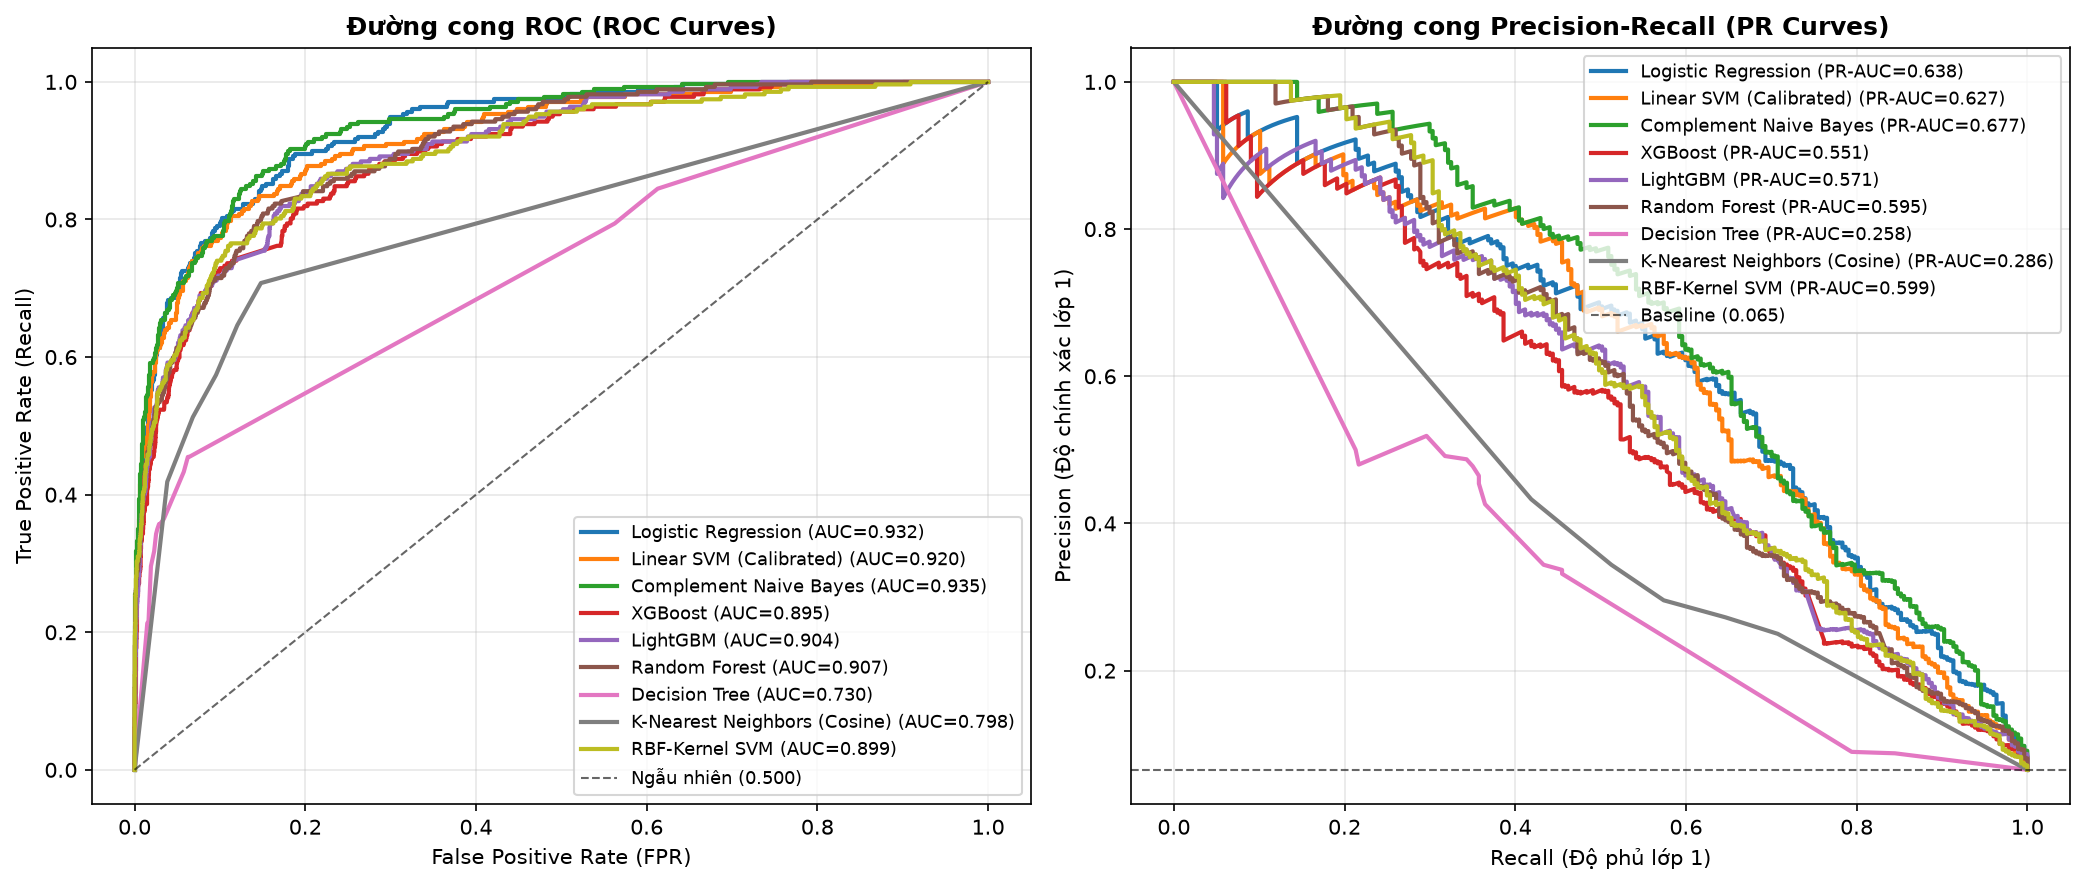

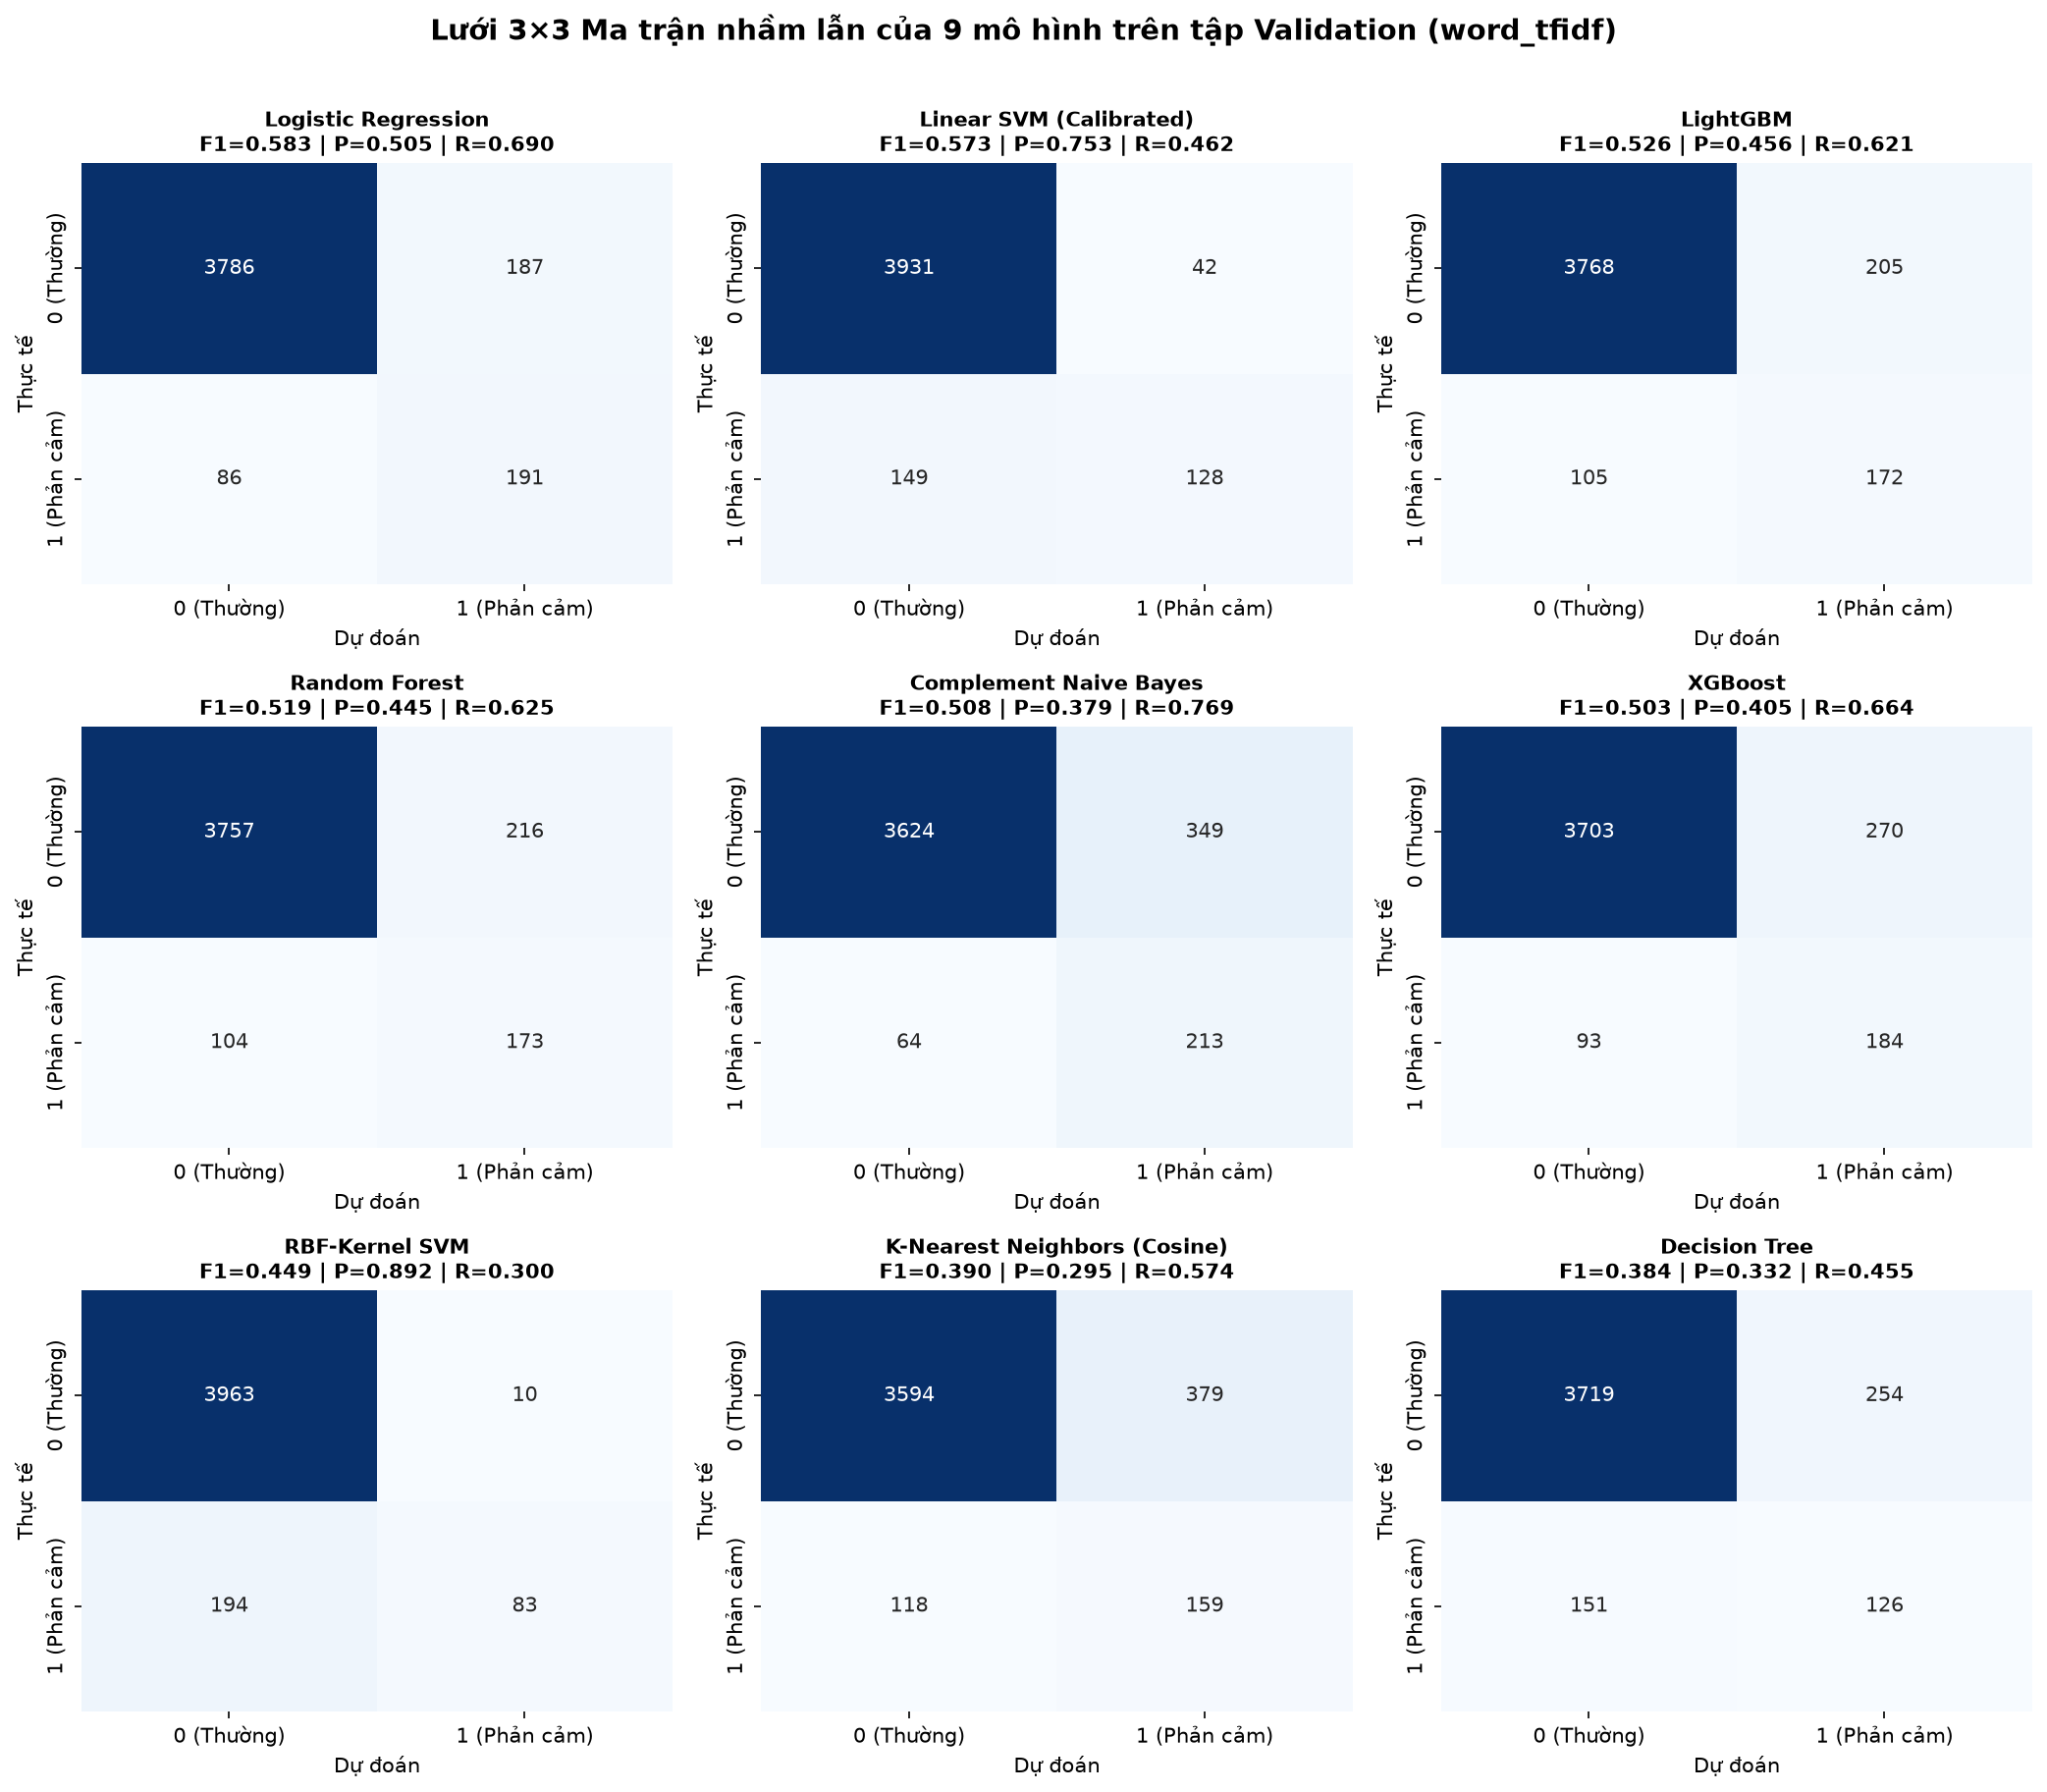

In [3]:
display(Image('reports/figures/P5_f1_prauc_bars.png'))
display(Image('reports/figures/P5_roc_pr_curves.png'))
display(Image('reports/figures/P5_confusion_grid_3x3.png'))

### Nhận xét: Vì sao Mô hình Tuyến tính thắng Mô hình Cây trên Văn bản TF-IDF thưa? 
- **Mô hình tuyến tính (`svm_linear`, `lr`) và `nb` vượt trội rõ rệt:** Với không gian đặc trưng TF-IDF chiều cao ($50,000 - 100,000$ chiều) và cực kỳ thưa (sparse > 99.9%), biên quyết định siêu phẳng tuyến tính tận dụng đồng thời hàng chục nghìn từ/cụm từ nhẹ mà không bị phân mảnh dữ liệu.
- **Kết hợp `word+char` giúp tăng thêm hiệu năng:** Việc bổ sung char n-gram (2–5 ký tự) giúp `svm_linear` và `lr` bắt được các biến thể viết tắt, kéo dài chữ hoặc cố tình viết sai chính tả để lách kiểm duyệt.
- **Vì sao Decision Tree / Random Forest / KNN thấp hơn?** Cây quyết định rẽ nhánh theo từng trục từ đơn lẻ (axis-aligned splits) trên ma trận 50,000 chiều thưa nên chỉ bao phủ được một vài từ khóa ở tầng nông và dễ overfit; trong khi KNN chịu ảnh hưởng của lời nguyền số chiều (*curse of dimensionality*).
- Ba mô hình dẫn đầu (`svm_linear`, `lr`, `nb`) được chọn đưa vào giai đoạn tinh chỉnh siêu tham số và tối ưu ngưỡng quyết định ở bước tiếp theo.